# Módulo IV – Aprendizado de Máquina · Aula 2: classificação e regressão
**Execução e interpretações de: Felipe Barbosa Vieira** — Turma SI 7/8 Noturno

Profa. Kadidja Valéria | UDF | Sistemas de Informação | 2026.2

Este caderno parte do [notebook didático da professora](laboratorio.ipynb) e mantém o mesmo código-base (semente 42, mesma simulação, mesma divisão). Acrescentei células para os exercícios de investigação e dois experimentos meus: **estabilidade da validação com repetições** e **curva de aprendizado**. Todos os registros são **sintéticos**; as relações foram definidas pela simulação e não são evidência sobre estudantes reais.

Funciona no Jupyter (executando de dentro de `notebooks/`) e no Colab (Ambiente de execução › Executar tudo). Figuras vão para `../assets/` quando a pasta existe; caso contrário, para `./assets/`.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     KFold, cross_validate, learning_curve)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score,
                             mean_absolute_error, r2_score)
SEMENTE = 42

PASTA_ASSETS = '../assets' if os.path.isdir('../assets') else './assets'
os.makedirs(PASTA_ASSETS, exist_ok=True)
def salvar(nome):
    caminho = os.path.join(PASTA_ASSETS, nome)
    plt.savefig(caminho, dpi=120, bbox_inches='tight')
    print('figura gravada:', caminho)

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__,
      '| matplotlib:', matplotlib.__version__, '| scikit-learn:', sklearn.__version__)

Python: 3.13.18
NumPy: 2.5.3 | pandas: 3.0.5 | matplotlib: 3.11.2 | scikit-learn: 1.9.1


## 1. Dados e pergunta de negócio
Pergunta: com os sinais disponíveis **ao fim da semana 4** (frequência, nota parcial e entregas), quais estudantes fictícios a equipe de apoio deveria procurar primeiro com um convite voluntário? Alvo: `evasao_fim_semestre` (0 = permaneceu, 1 = evadiu), conhecido só no fim do semestre.

A simulação é a mesma da professora. Depois de gerar os dados, confiro se eles coincidem com o CSV distribuído na pasta `dados/` (ou baixado do GitHub, no Colab).

In [2]:
rng = np.random.default_rng(SEMENTE)
n = 600
frequencia = rng.uniform(35, 100, n)
nota = rng.uniform(0, 10, n)
entregas = rng.integers(0, 9, n)
logit = -0.4 + (65 - frequencia)/18 + (5 - nota)/2 + (4 - entregas)/3
prob_simulada = 1 / (1 + np.exp(-logit))
alvo = rng.binomial(1, prob_simulada)
dados = pd.DataFrame({'frequencia_sem4': frequencia,
                      'nota_sem4': nota, 'entregas_sem4': entregas,
                      'evasao_fim_semestre': alvo})
dados.loc[rng.choice(n, 30, replace=False), 'nota_sem4'] = np.nan

FONTES_CSV = ['../dados/educacionais-sinteticos.csv',
              'https://raw.githubusercontent.com/lipefe11/Ciencia_Dados_Aprendizagem_Maquina/main/'
              'Aprendizado_de_Maquina/Aprendizado%20de%20m%C3%A1quina/dados/educacionais-sinteticos.csv']
conferido = None
for fonte in FONTES_CSV:
    try:
        csv = pd.read_csv(fonte)
        conferido = bool(np.allclose(csv.fillna(-1).values, dados.fillna(-1).values))
        print('CSV lido de', fonte, '| idêntico à simulação?', conferido)
        break
    except Exception as erro:
        print('não foi possível ler', fonte, '-', type(erro).__name__)

print(dados.head().round(2).to_string(index=False))
print('Dimensões:', dados.shape)
print('Ausentes por coluna:', dados.isna().sum().to_dict())
print('Classes (%):', dados['evasao_fim_semestre'].value_counts(normalize=True).mul(100).round(1).to_dict())

CSV lido de ../dados/educacionais-sinteticos.csv | idêntico à simulação? True
 frequencia_sem4  nota_sem4  entregas_sem4  evasao_fim_semestre
           85.31       4.78              0                    1
           63.53       7.61              5                    1
           90.81       9.03              6                    0
           80.33       7.21              4                    0
           41.12       9.63              3                    1
Dimensões: (600, 4)
Ausentes por coluna: {'frequencia_sem4': 0, 'nota_sem4': 30, 'entregas_sem4': 0, 'evasao_fim_semestre': 0}
Classes (%): {0: 59.0, 1: 41.0}


## 2. Separação antes de qualquer transformação
Holdout estratificado 75/25 com a semente 42. Toda exploração abaixo usa **somente o treino**.

Treino: 450 | Teste: 150
Evasão no treino: 0.411 | no teste: 0.407
       frequencia_sem4  nota_sem4  entregas_sem4
count           450.00     427.00         450.00
mean             67.19       5.13           4.10
std              18.66       2.91           2.65
min              35.48       0.01           0.00
25%              50.54       2.55           2.00
50%              67.27       5.15           4.00
75%              83.53       7.73           7.00
max              99.94       9.99           8.00

Taxa de evasão no treino por faixa de entregas:
                mean  size
entregas_sem4             
0-2            0.550   140
3-5            0.397   156
6-8            0.299   154


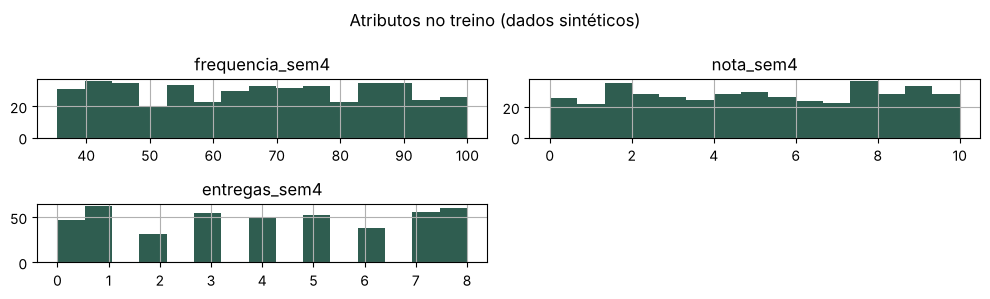

In [3]:
atributos = ['frequencia_sem4', 'nota_sem4', 'entregas_sem4']
X = dados[atributos]
y = dados['evasao_fim_semestre']
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEMENTE)
print('Treino:', len(X_treino), '| Teste:', len(X_teste))
print('Evasão no treino: %.3f | no teste: %.3f' % (y_treino.mean(), y_teste.mean()))
print(X_treino.describe().round(2))

# Exploração minha (só treino): taxa de evasão por faixa de entregas
faixa_entregas = pd.cut(X_treino['entregas_sem4'], bins=[-1, 2, 5, 8], labels=['0-2', '3-5', '6-8'])
print('\nTaxa de evasão no treino por faixa de entregas:')
print(y_treino.groupby(faixa_entregas, observed=True).agg(['mean', 'size']).round(3).to_string())

X_treino.hist(figsize=(10, 3), bins=15, color='#2f5d50')
plt.suptitle('Atributos no treino (dados sintéticos)')
plt.tight_layout(); plt.show()

## 3. Escolha da árvore somente no treino
Roteiro da professora (profundidade 2, 3, 5, None com folha 10) e, **antes de abrir o teste**, o exercício 1: grade completa com `min_samples_leaf` ∈ {5, 10, 20, 40}. A imputação pela mediana fica dentro do `Pipeline`, então é reaprendida em cada dobra.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

def arvore(profundidade, folha):
    return Pipeline([('imputador', SimpleImputer(strategy='median')),
                     ('arvore', DecisionTreeClassifier(max_depth=profundidade, min_samples_leaf=folha,
                                                       random_state=SEMENTE))])

grade = []
for folha in [5, 10, 20, 40]:
    for profundidade in [2, 3, 5, None]:
        s = cross_validate(arvore(profundidade, folha), X_treino, y_treino, cv=cv,
                           scoring='accuracy', return_train_score=True)
        grade.append({'folha': folha, 'profundidade': str(profundidade),
                      'treino_cv': s['train_score'].mean(),
                      'validacao_cv': s['test_score'].mean(),
                      'desvio': s['test_score'].std(),
                      'distancia': s['train_score'].mean() - s['test_score'].mean()})
grade = pd.DataFrame(grade)
print('Roteiro da professora (folha 10):')
print(grade[grade.folha == 10].round(4).to_string(index=False))
print('\nGrade completa (exercício 1):')
print(grade.round(4).to_string(index=False))

Roteiro da professora (folha 10):
 folha profundidade  treino_cv  validacao_cv  desvio  distancia
    10            2     0.7328        0.6844  0.0425     0.0483
    10            3     0.7678        0.7022  0.0257     0.0656
    10            5     0.8111        0.7222  0.0391     0.0889
    10         None     0.8206        0.7111  0.0477     0.1094

Grade completa (exercício 1):
 folha profundidade  treino_cv  validacao_cv  desvio  distancia
     5            2     0.7328        0.6844  0.0425     0.0483
     5            3     0.7706        0.7000  0.0233     0.0706
     5            5     0.8261        0.7222  0.0298     0.1039
     5         None     0.8678        0.7133  0.0215     0.1544
    10            2     0.7328        0.6844  0.0425     0.0483
    10            3     0.7678        0.7022  0.0257     0.0656
    10            5     0.8111        0.7222  0.0391     0.0889
    10         None     0.8206        0.7111  0.0477     0.1094
    20            2     0.7328        0

### Regra de escolha (definida antes de ver o teste)
1. Encontrar a maior média de validação.
2. Entre as configurações cuja média fica a menos de **um desvio-padrão** dessa melhor, escolher a de **menor distância treino–validação** (menos sinal de sobreajuste); em empate, a mais rasa e com folhas maiores.

Escolhi essa regra porque as médias da grade ficam muito próximas, e prefiro um modelo mais estável a um ganho que pode ser só sorte da divisão.

In [5]:
melhor = grade.loc[grade['validacao_cv'].idxmax()]
candidatas = grade[grade['validacao_cv'] >= melhor['validacao_cv'] - melhor['desvio']].copy()
candidatas['prof_num'] = candidatas['profundidade'].replace('None', '99').astype(int)
escolhida = candidatas.sort_values(['distancia', 'prof_num', 'folha'],
                                   ascending=[True, True, False], kind='stable').iloc[0]
prof = None if escolhida['profundidade'] == 'None' else int(escolhida['profundidade'])
folha = int(escolhida['folha'])
print('Maior média de validação: %.4f (folha %d, prof. %s), desvio %.4f'
      % (melhor['validacao_cv'], melhor['folha'], melhor['profundidade'], melhor['desvio']))
print('Candidatas dentro de 1 desvio:', len(candidatas))
print(candidatas.drop(columns='prof_num').round(4).to_string(index=False))
print('\nEscolhida: profundidade = %s, min_samples_leaf = %d' % (prof, folha))
print('Validação da escolhida: %.4f ± %.4f | distância treino–validação: %.4f'
      % (escolhida['validacao_cv'], escolhida['desvio'], escolhida['distancia']))
# referência na validação cruzada
s_ref = cross_validate(DummyClassifier(strategy='most_frequent'), X_treino, y_treino, cv=cv,
                       scoring='accuracy', return_train_score=True)
print('Referência (classe mais frequente) na VC: treino %.4f | validação %.4f ± %.4f'
      % (s_ref['train_score'].mean(), s_ref['test_score'].mean(), s_ref['test_score'].std()))

Maior média de validação: 0.7289 (folha 40, prof. 5), desvio 0.0303
Candidatas dentro de 1 desvio: 11
 folha profundidade  treino_cv  validacao_cv  desvio  distancia
     5            3     0.7706        0.7000  0.0233     0.0706
     5            5     0.8261        0.7222  0.0298     0.1039
     5         None     0.8678        0.7133  0.0215     0.1544
    10            3     0.7678        0.7022  0.0257     0.0656
    10            5     0.8111        0.7222  0.0391     0.0889
    10         None     0.8206        0.7111  0.0477     0.1094
    20            5     0.7900        0.7267  0.0480     0.0633
    20         None     0.7900        0.7267  0.0480     0.0633
    40            3     0.7661        0.7111  0.0351     0.0550
    40            5     0.7756        0.7289  0.0303     0.0467
    40         None     0.7756        0.7289  0.0303     0.0467

Escolhida: profundidade = 5, min_samples_leaf = 40
Validação da escolhida: 0.7289 ± 0.0303 | distância treino–validação: 0.0467
R

## 4. Avaliação final no teste (usado uma única vez)

Acurácia treino (ajuste completo): 0.7622
Acurácia teste: 0.7800 | referência: 0.5933
Matriz [linhas reais, colunas previstas]:
 [[70 19]
 [14 47]]
TN: 70 FP: 19 FN: 14 TP: 47
Acurácia pela matriz: (70 + 47) / 150 = 0.7800
Sensibilidade (classe 1): 47 / 61 = 0.7705
Especificidade (classe 0): 70 / 89 = 0.7865
Precisão (classe 1): 0.7121 | F1 (classe 1): 0.7402
figura gravada: ../assets/matriz-confusao.png


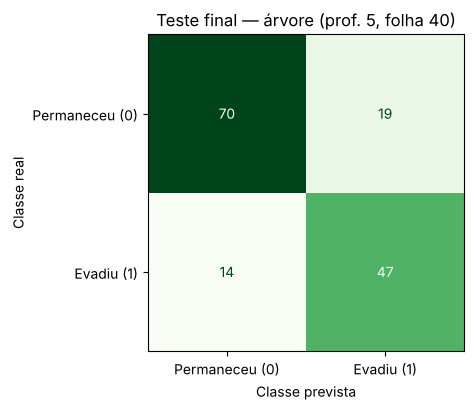

figura gravada: ../assets/arvore.png


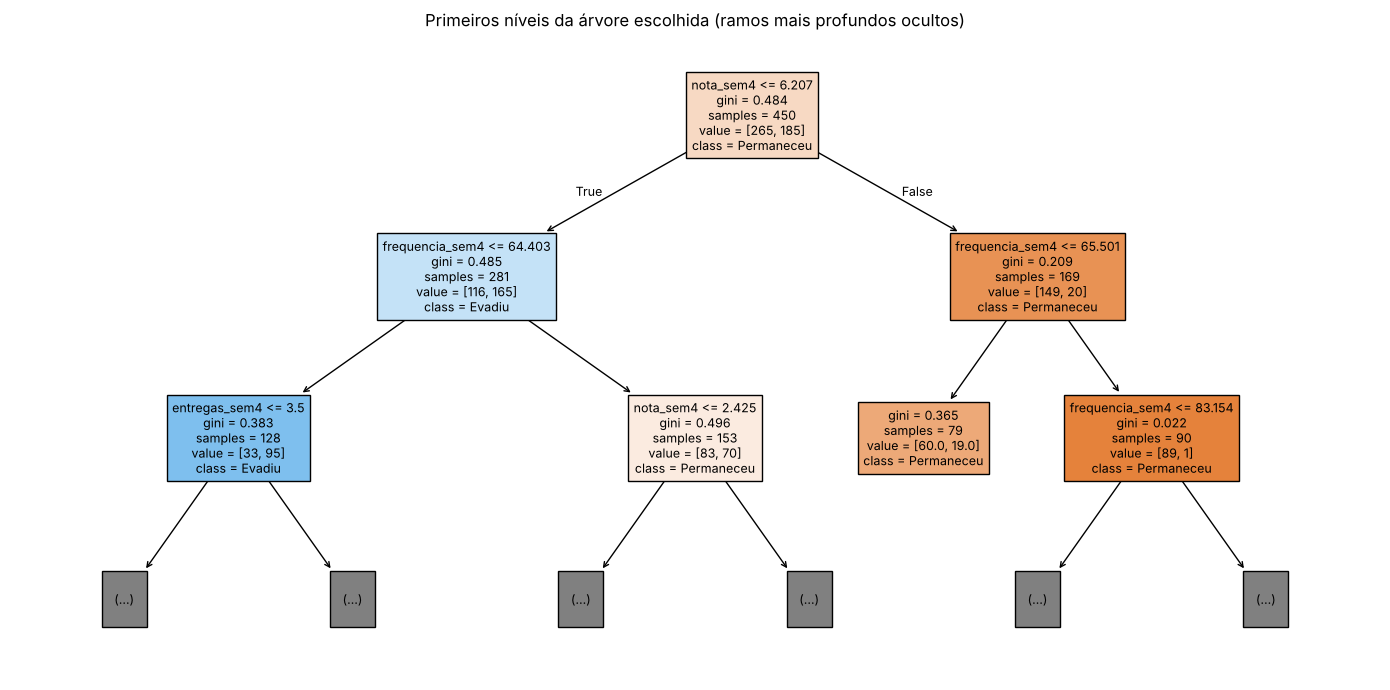

|--- nota_sem4 <= 6.21
|   |--- frequencia_sem4 <= 64.40
|   |   |--- entregas_sem4 <= 3.50
|   |   |   |--- class: 1
|   |   |--- entregas_sem4 >  3.50
|   |   |   |--- class: 1
|   |--- frequencia_sem4 >  64.40
|   |   |--- nota_sem4 <= 2.42
|   |   |   |--- class: 1
|   |   |--- nota_sem4 >  2.42
|   |   |   |--- truncated branch of depth 2
|--- nota_sem4 >  6.21
|   |--- frequencia_sem4 <= 65.50
|   |   |--- class: 0
|   |--- frequencia_sem4 >  65.50
|   |   |--- frequencia_sem4 <= 83.15
|   |   |   |--- class: 0
|   |   |--- frequencia_sem4 >  83.15
|   |   |   |--- class: 0

Importâncias: {'nota_sem4': 0.7, 'frequencia_sem4': 0.21, 'entregas_sem4': 0.09}


In [6]:
modelo = arvore(prof, folha).fit(X_treino, y_treino)
prev = modelo.predict(X_teste)
base = DummyClassifier(strategy='most_frequent').fit(X_treino, y_treino)
acc_treino = modelo.score(X_treino, y_treino)
acc = accuracy_score(y_teste, prev)
acc_base = accuracy_score(y_teste, base.predict(X_teste))
cm = confusion_matrix(y_teste, prev, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
sens = tp / (tp + fn); prec = precision_score(y_teste, prev); f1 = f1_score(y_teste, prev)
espec = tn / (tn + fp)
print(f'Acurácia treino (ajuste completo): {acc_treino:.4f}')
print(f'Acurácia teste: {acc:.4f} | referência: {acc_base:.4f}')
print('Matriz [linhas reais, colunas previstas]:\n', cm)
print('TN:', tn, 'FP:', fp, 'FN:', fn, 'TP:', tp)
print('Acurácia pela matriz: (%d + %d) / %d = %.4f' % (tn, tp, cm.sum(), (tn + tp) / cm.sum()))
print('Sensibilidade (classe 1): %d / %d = %.4f' % (tp, tp + fn, sens))
print('Especificidade (classe 0): %d / %d = %.4f' % (tn, tn + fp, espec))
print('Precisão (classe 1): %.4f | F1 (classe 1): %.4f' % (prec, f1))

fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay(cm, display_labels=['Permaneceu (0)', 'Evadiu (1)']).plot(cmap='Greens', ax=ax, colorbar=False)
ax.set_xlabel('Classe prevista'); ax.set_ylabel('Classe real')
ax.set_title('Teste final — árvore (prof. %s, folha %d)' % (prof, folha))
plt.tight_layout(); salvar('matriz-confusao.png'); plt.show()

plt.figure(figsize=(14, 7))
plot_tree(modelo.named_steps['arvore'], feature_names=atributos,
          class_names=['Permaneceu', 'Evadiu'], max_depth=2, filled=True, fontsize=9)
plt.title('Primeiros níveis da árvore escolhida (ramos mais profundos ocultos)')
plt.tight_layout(); salvar('arvore.png'); plt.show()

print(export_text(modelo.named_steps['arvore'], feature_names=atributos, max_depth=2))
importancias = pd.Series(modelo.named_steps['arvore'].feature_importances_, index=atributos)
print('Importâncias:', importancias.round(3).sort_values(ascending=False).to_dict())

**Comparação a posteriori (não é seleção).** Só para entender a diferença de erros, aplico ao teste também a configuração do roteiro (prof. 5, folha 10). Ela **não** substitui a escolhida: trocar de modelo depois de ver o teste exigiria um novo teste independente.

In [7]:
roteiro = arvore(5, 10).fit(X_treino, y_treino)
prev_rot = roteiro.predict(X_teste)
cm_rot = confusion_matrix(y_teste, prev_rot, labels=[0, 1])
print('Roteiro (prof. 5, folha 10) — acurácia teste %.4f | sensibilidade %.4f'
      % (accuracy_score(y_teste, prev_rot), recall_score(y_teste, prev_rot)))
print('Matriz do roteiro:\n', cm_rot)

Roteiro (prof. 5, folha 10) — acurácia teste 0.7800 | sensibilidade 0.6885
Matriz do roteiro:
 [[75 14]
 [19 42]]


## 5. Novos registros fictícios
A estimativa da árvore é a proporção de evadidos na folha, não uma probabilidade calibrada.

In [8]:
novos = pd.DataFrame({'frequencia_sem4': [72.0, 58.0, 95.0],
                      'nota_sem4': [6.0, 5.5, np.nan],
                      'entregas_sem4': [5, 3, 8]})
indice_1 = list(modelo.named_steps['arvore'].classes_).index(1)
novos['classe_prevista'] = modelo.predict(novos[atributos])
novos['estimativa_classe_1'] = modelo.predict_proba(novos[atributos])[:, indice_1].round(3)
print(novos.to_string(index=False))

 frequencia_sem4  nota_sem4  entregas_sem4  classe_prevista  estimativa_classe_1
            72.0        6.0              5                0                0.227
            58.0        5.5              3                1                0.881
            95.0        NaN              8                0                0.227


## 6. Exercícios de investigação no treino
**Exercício 4 — retirar um atributo** (com a configuração escolhida, validação cruzada no treino).

In [9]:
remocao = []
for retirado in [None] + atributos:
    cols = [a for a in atributos if a != retirado]
    s = cross_validate(arvore(prof, folha), X_treino[cols], y_treino, cv=cv, scoring='accuracy')
    remocao.append({'retirado': retirado or '(nenhum)',
                    'validacao_cv': s['test_score'].mean(), 'desvio': s['test_score'].std()})
remocao = pd.DataFrame(remocao)
remocao['variacao'] = remocao['validacao_cv'] - remocao['validacao_cv'].iloc[0]
print(remocao.round(4).to_string(index=False))

       retirado  validacao_cv  desvio  variacao
       (nenhum)        0.7289  0.0303    0.0000
frequencia_sem4        0.7311  0.0333    0.0022
      nota_sem4        0.6511  0.0303   -0.0778
  entregas_sem4        0.7244  0.0394   -0.0044


**Experimento próprio A — estabilidade da validação.** A validação cruzada com uma única semente gera uma média; repetindo a divisão em dobras 10 vezes (50 ajustes), vejo quanto essa média oscila e se a diferença entre a configuração da professora (prof. 5, folha 10) e a minha se sustenta.

In [10]:
rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEMENTE)
estab = []
for p_, f_ in [(5, 10), (prof, folha), (2, 10), (None, 5)]:
    s = cross_validate(arvore(p_, f_), X_treino, y_treino, cv=rep, scoring='accuracy')
    medias_por_repeticao = s['test_score'].reshape(10, 5).mean(axis=1)
    estab.append({'config': 'prof %s / folha %d' % (p_, f_),
                  'media_50': s['test_score'].mean(), 'desvio_50': s['test_score'].std(),
                  'menor_media_rep': medias_por_repeticao.min(),
                  'maior_media_rep': medias_por_repeticao.max()})
estab = pd.DataFrame(estab).drop_duplicates('config')
print(estab.round(4).to_string(index=False))

             config  media_50  desvio_50  menor_media_rep  maior_media_rep
  prof 5 / folha 10    0.7216     0.0352           0.7022           0.7422
  prof 5 / folha 40    0.7144     0.0372           0.6867           0.7289
  prof 2 / folha 10    0.6851     0.0383           0.6644           0.6978
prof None / folha 5    0.7064     0.0379           0.6800           0.7311


**Experimento próprio B — curva de aprendizado.** Treino a configuração escolhida com 20%, 40%, ..., 100% da parte de treino de cada dobra para ver se mais dados ajudariam.

 n_treino  treino  validacao  desvio_val
       72  0.6111     0.5889      0.0000
      144  0.7389     0.7156      0.0206
      216  0.7472     0.7267      0.0303
      288  0.7646     0.7089      0.0394
      360  0.7756     0.7289      0.0303


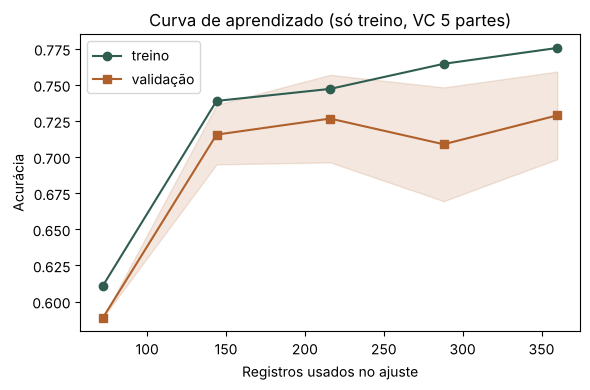

In [11]:
tamanhos, tr_sc, va_sc = learning_curve(arvore(prof, folha), X_treino, y_treino, cv=cv,
                                        train_sizes=np.linspace(0.2, 1.0, 5), scoring='accuracy')
curva = pd.DataFrame({'n_treino': tamanhos, 'treino': tr_sc.mean(axis=1),
                      'validacao': va_sc.mean(axis=1), 'desvio_val': va_sc.std(axis=1)})
print(curva.round(4).to_string(index=False))
plt.figure(figsize=(6, 4))
plt.plot(curva.n_treino, curva.treino, 'o-', color='#2f5d50', label='treino')
plt.plot(curva.n_treino, curva.validacao, 's-', color='#b0602a', label='validação')
plt.fill_between(curva.n_treino, curva.validacao - curva.desvio_val, curva.validacao + curva.desvio_val,
                 color='#b0602a', alpha=0.15)
plt.xlabel('Registros usados no ajuste'); plt.ylabel('Acurácia'); plt.legend()
plt.title('Curva de aprendizado (só treino, VC 5 partes)')
plt.tight_layout(); plt.show()

**Exercício 5 — classe muito majoritária.** Turma hipotética de 400 estudantes com 20 evasões (95% permanecem).

In [12]:
y_hip = np.array([0] * 380 + [1] * 20)
sempre_0 = np.zeros_like(y_hip)
print('Acurácia de sempre prever permanência:', accuracy_score(y_hip, sempre_0))
print('Matriz:\n', confusion_matrix(y_hip, sempre_0, labels=[0, 1]))
print('Sensibilidade:', recall_score(y_hip, sempre_0, zero_division=0))

Acurácia de sempre prever permanência: 0.95
Matriz:
 [[380   0]
 [ 20   0]]
Sensibilidade: 0.0


# Seção independente: regressão linear
## 7. Demanda semanal de uma biblioteca (sintética)

Treino: 225 | Teste: 75
MAE teste: 28.59 empréstimos/semana | R² teste: 0.8774
Referência (média do treino): MAE 84.73 | R² -0.0037
Coeficientes: {'usuarios_ativos': 0.348, 'horas_abertura': 2.297} | intercepto: 37.32


figura gravada: ../assets/regressao-observado-previsto.png


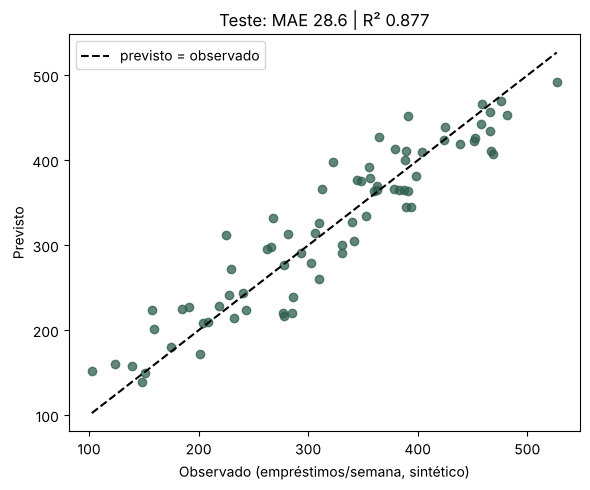

figura gravada: ../assets/regressao-residuos.png


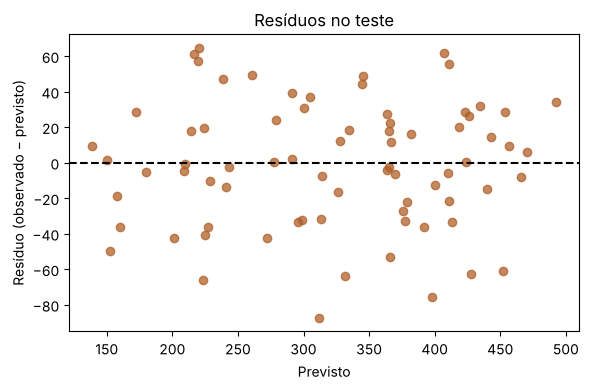

In [13]:
rng_reg = np.random.default_rng(SEMENTE)
reg = pd.DataFrame({'usuarios_ativos': rng_reg.uniform(100, 1000, 300),
                    'horas_abertura': rng_reg.uniform(20, 60, 300)})
reg['emprestimos_semana'] = (30 + 0.35*reg['usuarios_ativos'] +
                             2.5*reg['horas_abertura'] + rng_reg.normal(0, 35, 300))
atr_reg = ['usuarios_ativos', 'horas_abertura']
Xr, yr = reg[atr_reg], reg['emprestimos_semana']
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.25, random_state=SEMENTE)
regressor = Pipeline([('imputador', SimpleImputer(strategy='median')),
                      ('linear', LinearRegression())]).fit(Xr_tr, yr_tr)
pr = regressor.predict(Xr_te)
ref_reg = DummyRegressor(strategy='mean').fit(Xr_tr, yr_tr)
mae = mean_absolute_error(yr_te, pr); r2 = r2_score(yr_te, pr)
mae_base = mean_absolute_error(yr_te, ref_reg.predict(Xr_te))
r2_base = r2_score(yr_te, ref_reg.predict(Xr_te))
lin = regressor.named_steps['linear']
print('Treino:', len(Xr_tr), '| Teste:', len(Xr_te))
print(f'MAE teste: {mae:.2f} empréstimos/semana | R² teste: {r2:.4f}')
print(f'Referência (média do treino): MAE {mae_base:.2f} | R² {r2_base:.4f}')
print('Coeficientes:', {k: round(float(c), 4) for k, c in zip(atr_reg, lin.coef_)}, '| intercepto: %.2f' % lin.intercept_)

plt.figure(figsize=(6, 5))
plt.scatter(yr_te, pr, alpha=0.75, color='#2f5d50')
lim = [min(yr_te.min(), pr.min()), max(yr_te.max(), pr.max())]
plt.plot(lim, lim, 'k--', label='previsto = observado')
plt.xlabel('Observado (empréstimos/semana, sintético)'); plt.ylabel('Previsto')
plt.title('Teste: MAE %.1f | R² %.3f' % (mae, r2)); plt.legend()
plt.tight_layout(); salvar('regressao-observado-previsto.png'); plt.show()

residuos = yr_te - pr
plt.figure(figsize=(6, 4))
plt.scatter(pr, residuos, alpha=0.75, color='#b0602a')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Previsto'); plt.ylabel('Resíduo (observado − previsto)')
plt.title('Resíduos no teste'); plt.tight_layout(); salvar('regressao-residuos.png'); plt.show()

## 8. Exercícios da regressão

In [14]:
# (a) erros absolutos dos cinco primeiros registros do teste
cinco = pd.DataFrame({'real': yr_te, 'previsto': pr, 'erro_absoluto': np.abs(yr_te - pr)}).head()
print(cinco.round(2)); print('Média desses 5 erros: %.2f' % cinco['erro_absoluto'].mean())

# (b) resíduos: resumo e comportamento por faixa de valor previsto
print('\nResíduos: média %.2f | desvio %.2f | mín %.2f | máx %.2f'
      % (residuos.mean(), residuos.std(), residuos.min(), residuos.max()))
faixa_prev = pd.qcut(pr, 3, labels=['previsão baixa', 'previsão média', 'previsão alta'])
print(pd.DataFrame({'faixa': faixa_prev, 'res': residuos.values, 'abs': np.abs(residuos.values)})
        .groupby('faixa', observed=True).agg(media_residuo=('res', 'mean'), mae=('abs', 'mean'), n=('res', 'size'))
        .round(2).to_string())

# (c) retirar um atributo, validação cruzada só no treino
kf = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
linhas = []
for cols in [atr_reg, ['usuarios_ativos'], ['horas_abertura']]:
    s = cross_validate(Pipeline([('imputador', SimpleImputer(strategy='median')), ('linear', LinearRegression())]),
                       Xr_tr[cols], yr_tr, cv=kf, scoring=['neg_mean_absolute_error', 'r2'])
    linhas.append({'atributos': ' + '.join(cols), 'MAE_cv': -s['test_neg_mean_absolute_error'].mean(),
                   'desvio_MAE': s['test_neg_mean_absolute_error'].std(), 'R2_cv': s['test_r2'].mean()})
remocao_reg = pd.DataFrame(linhas)
print(); print(remocao_reg.round(3).to_string(index=False))

# (d) extrapolação: dentro e fora do domínio simulado (100–1000 usuários; 20–60 h)
fora = pd.DataFrame({'usuarios_ativos': [500, 2000, 10000], 'horas_abertura': [40, 80, 168]})
fora['previsao'] = regressor.predict(fora).round(1)
print(); print(fora.to_string(index=False))

       real  previsto  erro_absoluto
203  208.90    209.40           0.50
266  277.71    277.32           0.39
152  190.95    227.18          36.23
9    229.67    271.95          42.29
233  359.77    363.62           3.85
Média desses 5 erros: 16.65

Resíduos: média -1.28 | desvio 35.47 | mín -87.24 | máx 64.59
                media_residuo    mae   n
faixa                                   
previsão baixa          -0.47  29.00  25
previsão média          -1.22  28.04  25
previsão alta           -2.16  28.74  25

                       atributos  MAE_cv  desvio_MAE  R2_cv
usuarios_ativos + horas_abertura  28.892       1.771  0.867
                 usuarios_ativos  35.904       3.192  0.798
                  horas_abertura  83.728       5.357  0.048

 usuarios_ativos  horas_abertura  previsao
             500              40     303.2
            2000              80     917.1
           10000             168    3903.1


In [15]:
resultados = {
    'autor': 'Felipe Barbosa Vieira',
    'csv_identico_simulacao': conferido,
    'profundidade': prof, 'min_samples_leaf': folha,
    'validacao_escolhida': float(escolhida['validacao_cv']), 'desvio_validacao_escolhida': float(escolhida['desvio']),
    'treino_cv_escolhida': float(escolhida['treino_cv']),
    'referencia_validacao_cv': float(s_ref['test_score'].mean()),
    'acuracia_treino': float(acc_treino), 'acuracia_teste': float(acc), 'acuracia_referencia': float(acc_base),
    'matriz_confusao': cm.tolist(), 'matriz_roteiro_posteriori': cm_rot.tolist(), 'sensibilidade_classe1': float(sens), 'especificidade_classe0': float(espec),
    'precisao_classe1': float(prec), 'f1_classe1': float(f1),
    'importancias': {k: float(v) for k, v in importancias.items()},
    'grade': grade.round(4).to_dict(orient='records'),
    'remocao_atributos': remocao.round(4).to_dict(orient='records'),
    'estabilidade_repetida': estab.round(4).to_dict(orient='records'),
    'curva_aprendizado': curva.round(4).to_dict(orient='records'),
    'mae': float(mae), 'r2': float(r2), 'mae_referencia': float(mae_base), 'r2_referencia': float(r2_base),
    'coeficientes_regressao': [float(c) for c in lin.coef_], 'intercepto': float(lin.intercept_),
    'residuos': {'media': float(residuos.mean()), 'desvio': float(residuos.std()),
                 'min': float(residuos.min()), 'max': float(residuos.max())},
    'remocao_regressao': remocao_reg.round(3).to_dict(orient='records'),
    'extrapolacao': fora.to_dict(orient='records'),
    'python': sys.version.split()[0], 'sklearn': sklearn.__version__, 'pandas': pd.__version__,
    'numpy': np.__version__, 'matplotlib': matplotlib.__version__}
with open('resultados_execucao.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2)
print('resultados_execucao.json gravado')

resultados_execucao.json gravado


## Interpretação (Felipe)

**Classificação — o que foi calculado**
- Os dados simulados coincidem com o CSV da disciplina (`True`). 450 registros de treino e 150 de teste, com evasão de 41,1% e 40,7%.
- Na grade de 16 combinações, as médias de validação ficaram entre 0,684 e 0,729. A maior média foi a da folha 40 com profundidade 5 (0,7289 ± 0,0303). Pela minha regra (ficar a menos de um desvio da melhor e preferir a menor distância treino–validação), a escolha caiu na **mesma** configuração. Distância treino–validação de 0,047, contra 0,154 da árvore livre com folha 5.
- Teste (usado uma vez): acurácia 0,78 contra 0,593 da referência. Matriz: TN = 70, FP = 19, FN = 14, TP = 47. Sensibilidade 47/61 = 0,770 e precisão 47/66 = 0,712.

**Interpretação**
- A acurácia de teste é igual à da configuração do roteiro (prof. 5, folha 10, que também dá 0,78 com essa semente), mas os erros se distribuem de outro jeito. Esta árvore deixa escapar menos evasões (14 FN) e, em troca, faz mais convites desnecessários (19 FP). Para um convite voluntário de apoio, prefiro essa troca.
- A acurácia no treino completo (0,762) ficou um pouco **abaixo** da de teste (0,78). Com folhas de 40 registros a árvore quase não decora o treino, e 150 registros de teste ainda deixam margem de sorte. Não interpreto isso como "o modelo é melhor em dados novos".
- **Experimento A (repetições):** com 10 repetições da validação em 5 partes, a folha 40 teve média 0,714 e a folha 10 teve 0,722. A vantagem que a folha 40 tinha na validação única **desapareceu**: ela era uma flutuação da divisão em dobras. As duas configurações são equivalentes dentro da variação. Mantive a escolha porque ela foi feita antes do teste, e trocar agora seria escolher com base em informação nova. Registro a lição: uma diferença de 0,007 não justifica preferir um modelo.
- **Experimento B (curva de aprendizado):** com 72 registros a árvore de folha 40 não consegue dividir e prevê só a classe majoritária (0,589). A partir de cerca de 216 registros a validação se estabiliza em torno de 0,71–0,73. Mais dados simulados do mesmo tipo trariam pouco ganho. O limite está no ruído do alvo, não no tamanho da amostra.
- **Retirada de atributos:** sem a nota a validação cai 0,078. Sem frequência ou sem entregas, as mudanças (+0,002 e −0,004) ficam dentro do desvio. Isso mostra utilidade para **prever nesta simulação**, não causa.

**Regressão**
- MAE de 28,59 empréstimos/semana contra 84,73 da média do treino; R² de 0,877. A referência tem R² de −0,004 no teste porque usa a média do treino, não a do teste.
- Os resíduos têm média −1,28 e desvio 35,5. O MAE é parecido nas três faixas de previsão (29,0; 28,0; 28,7), sem sinal de curvatura.
- Sem `usuarios_ativos`, o MAE de validação sobe de 28,9 para 83,7. Sem `horas_abertura`, sobe para 35,9.
- Extrapolação: para 2.000 usuários e 80 h o modelo responde 917, e para 10.000 usuários e 168 h (a semana inteira) responde 3.903. São números que a simulação nunca mostrou. O modelo não "sabe" que está fora do domínio.

**Limites:** dados sintéticos, uma única divisão de teste e nenhum grupo real para auditar equidade.

## Referências
- SCIKIT-LEARN. *User Guide* (Decision Trees; Cross-validation; Learning curve). https://scikit-learn.org/stable/user_guide.html. Acesso em: 16 out. 2026.
- SCIKIT-LEARN. *Common pitfalls and recommended practices*. https://scikit-learn.org/stable/common_pitfalls.html. Acesso em: 16 out. 2026.
- Notebook didático da Profa. Kadidja Valéria (Módulo IV, UDF, 2026.2).